In [1]:
import pandas as pd
import itertools
import json

# 1. Load your uploaded dataset
# Make sure the filename matches exactly what you uploaded
filename = "/content/drive/MyDrive/dataset/cleanedPos_filtered_marma_dictionary - filtered_marma_dictionary.csv.csv"
df = pd.read_csv(filename)

# 2. Function to Clean POS Tags (Fixing the "English Grammar" issue)
# Maps complex tags like "JJ NN" to simple categories like "Noun"
def clean_pos_tag(pos):
    pos = str(pos).strip().upper()
    if 'NN' in pos: return 'Noun'      # Any Noun (NN, NNP, NNS) -> Noun
    if 'VB' in pos: return 'Verb'      # Any Verb (VB, VBD) -> Verb
    if 'JJ' in pos: return 'Adjective' # Adjectives
    if 'RB' in pos: return 'Adverb'    # Adverbs
    if 'PRP' in pos: return 'Pronoun'  # Pronouns
    return pos # Keep others as is if unsure

df['Cleaned_POS'] = df['POS'].apply(clean_pos_tag)

# 3. Define the 4 columns representing the languages
# We map the CSV column names to "Human Readable" language names for the prompt
cols = {
    'Marma_English_Transliterate': 'Marma (English Script)',
    'Marma_Bangla_Transliterate': 'Marma (Bangla Script)',
    'Bangla_Translation': 'Bangla',
    'English_Translation': 'English'
}

# 4. Generate the "10+ Directions" Dataset
alpaca_data = []

for idx, row in df.iterrows():
    pos_label = row['Cleaned_POS']
    values = {k: row[k] for k in cols.keys()}

    # --- PART A: Translation Tasks (All Permutations) ---
    # This generates: Marma->Eng, Eng->Marma, Bangla->Marma, etc.
    for source_col, target_col in itertools.permutations(cols.keys(), 2):
        source_lang = cols[source_col]
        target_lang = cols[target_col]
        source_text = str(values[source_col]).strip()
        target_text = str(values[target_col]).strip()

        if source_text and target_text and source_text != 'nan':
            alpaca_data.append({
                "instruction": f"Translate this {source_lang} word into {target_lang}.",
                "input": source_text,
                "output": target_text
            })

    # --- PART B: POS Tagging Tasks (For ALL Languages) ---
    # This teaches the model to recognize a Noun in Marma, Bangla, AND English
    for col, lang in cols.items():
        text = str(values[col]).strip()
        if text and text != 'nan':
            alpaca_data.append({
                "instruction": f"Identify the Part of Speech (POS) for this {lang} word.",
                "input": text,
                "output": pos_label
            })

# 5. Save as JSONL (Ready for Unsloth/LLaMA)
output_file = "marma_instruct_dataset.jsonl"
with open(output_file, 'w', encoding='utf-8') as f:
    for entry in alpaca_data:
        json.dump(entry, f, ensure_ascii=False)
        f.write('\n')

print(f"Success! Created {len(alpaca_data)} training instructions from {len(df)} original rows.")

Success! Created 11536 training instructions from 721 original rows.


In [2]:
# 1. Install Unsloth (Updated for Speed)
import torch
try:
    major_version, minor_version = torch.cuda.get_device_capability()
except:
    major_version, minor_version = 8, 0 # Default if no GPU found, though you need GPU

# We remove the "xformers<0.0.27" constraint to avoid building from source
!pip install "unsloth[colab-new] @ git+https://github.com/unslothai/unsloth.git"
!pip install --no-deps xformers peft accelerate bitsandbytes

# 2. Imports & Model Loading
from unsloth import FastLanguageModel
import torch
from datasets import load_dataset
from transformers import TrainingArguments
from trl import SFTTrainer

max_seq_length = 2048
dtype = None
load_in_4bit = True

model, tokenizer = FastLanguageModel.from_pretrained(
    model_name = "unsloth/llama-3-8b-bnb-4bit",
    max_seq_length = max_seq_length,
    dtype = dtype,
    load_in_4bit = load_in_4bit,
)

# 3. Anti-Overfitting Setup (Dropout & Decay)
model = FastLanguageModel.get_peft_model(
    model,
    r = 16,
    target_modules = ["q_proj", "k_proj", "v_proj", "o_proj",
                      "gate_proj", "up_proj", "down_proj",],
    lora_alpha = 16,
    lora_dropout = 0.1,  # Drops 10% of neurons to prevent memorization
    bias = "none",
    use_gradient_checkpointing = "unsloth",
    random_state = 3407,
    use_rslora = False,
    loftq_config = None,
)

# 4. Load & Split Data
# Note: Ensure your Google Drive is mounted before running this!
# from google.colab import drive
# drive.mount('/content/drive')

dataset = load_dataset("json", data_files="/content/drive/MyDrive/dataset/marma_instruct_dataset.jsonl", split="train")
dataset = dataset.train_test_split(test_size=0.05) # 95% Train, 5% Validation

alpaca_prompt = """Below is an instruction that describes a task, paired with an input that provides further context. Write a response that appropriately completes the request.

### Instruction:
{}

### Input:
{}

### Response:
{}"""

def formatting_prompts_func(examples):
    instructions = examples["instruction"]
    inputs       = examples["input"]
    outputs      = examples["output"]
    texts = []
    for instruction, input, output in zip(instructions, inputs, outputs):
        text = alpaca_prompt.format(instruction, input, output) + tokenizer.eos_token
        texts.append(text)
    return { "text" : texts, }

train_dataset = dataset["train"].map(formatting_prompts_func, batched = True)
eval_dataset  = dataset["test"].map(formatting_prompts_func, batched = True)

# 5. Train with Monitoring
trainer = SFTTrainer(
    model = model,
    tokenizer = tokenizer,
    train_dataset = train_dataset,
    eval_dataset = eval_dataset,
    dataset_text_field = "text",
    max_seq_length = max_seq_length,
    dataset_num_proc = 2,
    packing = False,
    args = TrainingArguments(
        per_device_train_batch_size = 2,
        gradient_accumulation_steps = 4,
        warmup_steps = 10,

        # PREVENT OVERFITTING:
        num_train_epochs = 1,
        learning_rate = 5e-5,
        weight_decay = 0.05,

        # MONITORING:
        eval_strategy = "steps",
        eval_steps = 50,
        logging_steps = 50,

        fp16 = not torch.cuda.is_bf16_supported(),
        bf16 = torch.cuda.is_bf16_supported(),
        optim = "adamw_8bit",
        lr_scheduler_type = "linear",
        seed = 3407,
        output_dir = "outputs",
    ),
)

trainer.train()

  Cloning https://github.com/unslothai/unsloth.git to /tmp/pip-install-wme0931b/unsloth_4f6c674877264b4baeff0f63bdfa0047
  Running command git clone --filter=blob:none --quiet https://github.com/unslothai/unsloth.git /tmp/pip-install-wme0931b/unsloth_4f6c674877264b4baeff0f63bdfa0047
  Resolved https://github.com/unslothai/unsloth.git to commit b2143c6b61221bf7717311f640f2cdf51ecefa8b
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
==((====))==  Unsloth 2025.12.5: Fast Llama patching. Transformers: 4.57.3.
   \\   /|    NVIDIA L4. Num GPUs = 1. Max memory: 22.161 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.9.0+cu126. CUDA: 8.9. CUDA Toolkit: 12.6. Triton: 3.5.0
\        /    Bfloat16 = TRUE. FA [Xformers = 0.0.33.post2. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Map:   0%|          | 0/10959 [00:00<?, ? examples/s]

Map:   0%|          | 0/577 [00:00<?, ? examples/s]

Unsloth: Tokenizing ["text"] (num_proc=16):   0%|          | 0/10959 [00:00<?, ? examples/s]

Unsloth: Tokenizing ["text"] (num_proc=16):   0%|          | 0/577 [00:00<?, ? examples/s]

The model is already on multiple devices. Skipping the move to device specified in `args`.
==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 10,959 | Num Epochs = 1 | Total steps = 1,370
O^O/ \_/ \    Batch size per device = 2 | Gradient accumulation steps = 4
\        /    Data Parallel GPUs = 1 | Total batch size (2 x 4 x 1) = 8
 "-____-"     Trainable parameters = 41,943,040 of 8,072,204,288 (0.52% trained)
/usr/local/lib/python3.12/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results
wandb: Enter your choice:

... (5 outputs left out)

Step,Training Loss,Validation Loss
50,1.370900,0.441803
100,0.367700,0.353421
150,0.332000,0.330765
200,0.332900,0.316002
250,0.307500,0.303818
300,0.307900,0.295122
350,0.293700,0.282581
400,0.280200,0.277575
450,0.272500,0.268288
500,0.265800,0.262697


Unsloth: Not an error, but LlamaForCausalLM does not accept `num_items_in_batch`.
Using gradient accumulation will be very slightly less accurate.
Read more on gradient accumulation issues here: https://unsloth.ai/blog/gradient


eval/loss,█▅▅▄▄▄▃▃▃▃▃▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁
eval/runtime,▂▂▁▂▄▃▂▃▂▂▃▂▂▃▃▃▃▃▂▂▄█▂▁▂▁▁
eval/samples_per_second,▇▇█▇▅▆▇▆▇▇▆▇▇▆▆▆▆▆▇▇▅▁▇█▇██
eval/steps_per_second,▇▇█▇▅▆▇▆▇▇▆▇▇▆▆▆▆▆▇▇▅▁▇█▇██
train/epoch,▁▁▁▁▂▂▂▂▂▂▃▃▃▃▃▄▄▄▄▄▄▅▅▅▅▆▆▆▆▆▆▇▇▇▇▇▇███
train/global_step,▁▁▁▁▂▂▂▂▃▃▃▃▃▃▄▄▄▄▄▄▅▅▅▅▆▆▆▆▆▆▇▇▇▇▇▇▇███
train/grad_norm,█▃▁▂▁▁▁▂▃▃▅▂▄▃▄▃▃▃▃▄▄▅▄▄▃▂▃
train/learning_rate,██▇▇▇▇▆▆▆▆▅▅▅▅▄▄▄▃▃▃▃▂▂▂▂▁▁
train/loss,█▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
eval/loss,0.20582
eval/runtime,51.8985


TrainOutput(global_step=1370, training_loss=0.29435912710036677, metrics={'train_runtime': 4908.173, 'train_samples_per_second': 2.233, 'train_steps_per_second': 0.279, 'total_flos': 3.229143190995763e+16, 'train_loss': 0.29435912710036677, 'epoch': 1.0})

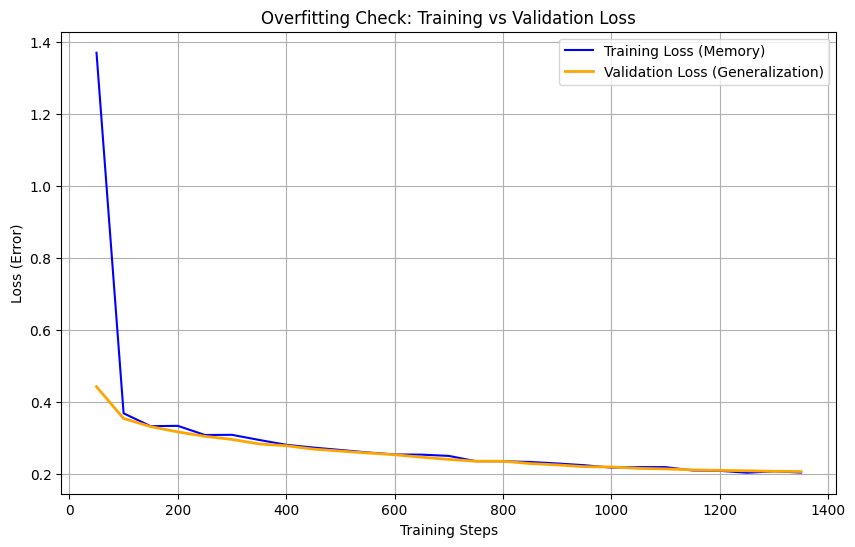

In [3]:
import matplotlib.pyplot as plt

# 1. Extract logs
history = trainer.state.log_history
train_loss = []
eval_loss = []
train_steps = []
eval_steps = []

for entry in history:
    if 'loss' in entry:
        train_loss.append(entry['loss'])
        train_steps.append(entry['step'])
    if 'eval_loss' in entry:
        eval_loss.append(entry['eval_loss'])
        eval_steps.append(entry['step'])

# 2. Plot the Graph
plt.figure(figsize=(10, 6))
plt.plot(train_steps, train_loss, label='Training Loss (Memory)', color='blue')
plt.plot(eval_steps, eval_loss, label='Validation Loss (Generalization)', color='orange', linewidth=2)
plt.xlabel('Training Steps')
plt.ylabel('Loss (Error)')
plt.title('Overfitting Check: Training vs Validation Loss')
plt.legend()
plt.grid(True)
plt.show()

In [4]:
# 1. Mount Google Drive (if you haven't already)
from google.colab import drive
drive.mount('/content/drive')

# 2. Define the folder path in your Drive
# You can change "Marma_Translator_Model" to any name you prefer
save_path = "/content/drive/MyDrive/Marma_Translator_Model"

# 3. Save the Model and Tokenizer
print(f"Saving model to {save_path}...")
model.save_pretrained(save_path)
tokenizer.save_pretrained(save_path)

print("✅ Success! Model saved to Google Drive.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Saving model to /content/drive/MyDrive/Marma_Translator_Model...
✅ Success! Model saved to Google Drive.


In [5]:
# 1. Install Evaluation Libraries
!pip install evaluate sacrebleu

# 2. Setup & Imports
from unsloth import FastLanguageModel
import torch
from tqdm.auto import tqdm
import evaluate
import numpy as np

# Enable inference mode (2x faster generation)
FastLanguageModel.for_inference(model)

# 3. Generate Responses on the Test Set
def get_predictions(dataset, model, tokenizer, batch_size=8):
    model.eval()

    inputs = dataset["input"]
    instructions = dataset["instruction"]
    references = dataset["output"]

    predictions = []

    # Create prompts (Leave 'Response' empty for the model to fill)
    prompts = []
    for instruct, inp in zip(instructions, inputs):
        # Re-using the alpaca_prompt format from your training cell
        prompts.append(alpaca_prompt.format(instruct, inp, ""))

    # Generate in batches to speed it up
    for i in tqdm(range(0, len(prompts), batch_size), desc="Generating Responses"):
        batch_prompts = prompts[i:i+batch_size]

        # Tokenize
        input_ids = tokenizer(batch_prompts, return_tensors="pt", padding=True).to("cuda")

        # Generate
        with torch.no_grad():
            outputs = model.generate(
                **input_ids,
                max_new_tokens = 64,  # Adjust if translations are long
                use_cache = True,
                pad_token_id = tokenizer.eos_token_id
            )

        # Decode
        decoded_batch = tokenizer.batch_decode(outputs, skip_special_tokens=True)

        # Extract just the response part
        for text in decoded_batch:
            # Split by "Response:\n" and take the last part
            if "### Response:\n" in text:
                response = text.split("### Response:\n")[-1].strip()
            else:
                response = text.strip()
            predictions.append(response)

    return predictions, references

# Run Generation (using the 'test' split defined earlier)
print("Generating predictions on test set...")
predictions, references = get_predictions(dataset["test"], model, tokenizer)

# 4. Calculate Scores
bleu = evaluate.load("bleu")
results_bleu = bleu.compute(predictions=predictions, references=references)

# Accuracy (Exact Match) - strict checking
# Good for POS tagging, harsh for translation
accuracy = np.mean([1 if p.strip() == r.strip() else 0 for p, r in zip(predictions, references)])

# 5. Print Results
print("\n" + "="*30)
print(f"✅ BLEU Score:       {results_bleu['bleu']:.4f}")
print(f"✅ Exact Accuracy:   {accuracy*100:.2f}%")
print("="*30)

# 6. Show Examples
print("\n--- Example Predictions ---")
for i in range(5):
    print(f"Input:    {dataset['test'][i]['input']}")
    print(f"Actual:   {references[i]}")
    print(f"Model:    {predictions[i]}")
    print("-" * 20)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.8/51.8 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 9.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 104.1/104.1 kB 9.7 MB/s eta 0:00:00
Generating predictions on test set...


Generating Responses:   0%|          | 0/73 [00:00<?, ?it/s]


✅ BLEU Score:       0.0000
✅ Exact Accuracy:   28.25%

--- Example Predictions ---
Input:    ব্যাগ
Actual:   Noun
Model:    Noun
--------------------
Input:    shopping
Actual:   jipruho
Model:    khungcha
--------------------
Input:    সে
Actual:   Pronoun
Model:    Pronoun
--------------------
Input:    দামাদে
Actual:   here
Model:    all
--------------------
Input:    আমার
Actual:   ekri
Model:    khungbong
--------------------



--- Running Detailed Evaluation ---
Evaluating on 500 samples...


Checking Answers:   0%|          | 0/500 [00:00<?, ?it/s]


RESULTS SUMMARY
📘 POS Tagging Accuracy:   63.04%  (Grammar Logic)
📕 Translation Accuracy:   29.28%  (Exact Word Match)

--- Generating Graph ---


/tmp/ipython-input-932761120.py:101: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x='Task', y='Accuracy', data=df_viz, palette=['#FF5722', '#3F51B5'])


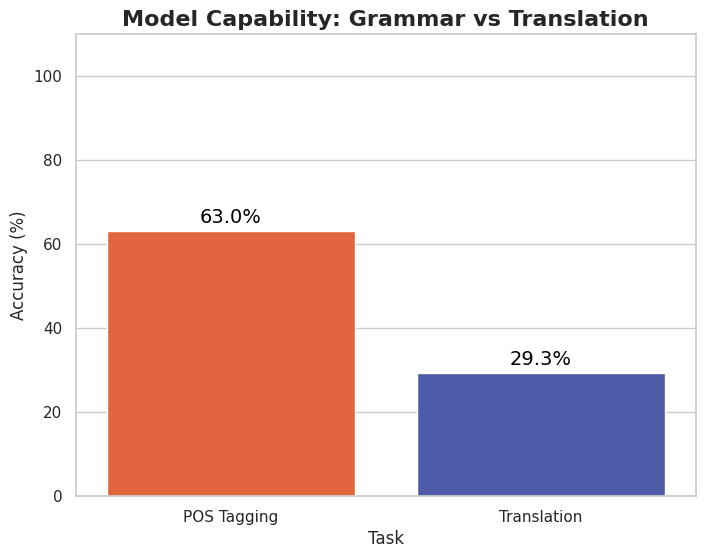

In [7]:
# ==============================================================================
# STEP 8: EVALUATION & VISUALIZATION (POS vs Translation)
# ==============================================================================

import string
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
from tqdm.auto import tqdm
from unsloth import FastLanguageModel

print("\n--- Running Detailed Evaluation ---")

# 1. Setup Data & Metrics
# We use the 'test' split defined in your earlier training block
test_data = eval_dataset # Changed from dataset["test"]
EOS_TOKEN = tokenizer.eos_token

metrics = {
    "pos_correct": 0,
    "pos_total": 0,
    "trans_exact": 0,
    "trans_total": 0
}

# 2. Evaluate on a subset (for speed) or full set
# Change to len(test_data) if you want to wait for the whole thing
eval_subset_size = 500
eval_subset = test_data.select(range(min(eval_subset_size, len(test_data))))

print(f"Evaluating on {len(eval_subset)} samples...")

# Normalize function: Removes punctuation and casing for fair comparison
def normalize_text(text):
    if not text: return ""
    # Remove punctuation
    text = text.translate(str.maketrans('', '', string.punctuation))
    # Remove extra spaces and lowercase
    return text.lower().strip()

# Enable faster inference
FastLanguageModel.for_inference(model)

# 3. Running the Loop
for item in tqdm(eval_subset, desc="Checking Answers"):
    # Reconstruct the prompt from the dataset text
    full_text = item["text"]

    # Split prompt and target answer
    # Note: We split by "Response:\n"
    if "### Response:\n" not in full_text:
        continue # Skip malformed data

    prompt_part = full_text.split("### Response:\n")[0] + "### Response:\n"
    target_part = full_text.split("### Response:\n")[1].replace(EOS_TOKEN, "").strip()

    # Generate Prediction
    inputs = tokenizer([prompt_part], return_tensors="pt").to("cuda")

    # max_new_tokens=64 is enough for words/short phrases
    outputs = model.generate(**inputs, max_new_tokens=64, use_cache=True)

    # Decode and clean prediction
    prediction = tokenizer.batch_decode(outputs, skip_special_tokens=True)[0]
    prediction = prediction.split("### Response:\n")[-1].strip()

    # 4. Score based on Task Type
    # We check if the instruction was about "Part of Speech"
    if "Part of Speech" in prompt_part:
        metrics["pos_total"] += 1
        if normalize_text(prediction) == normalize_text(target_part):
            metrics["pos_correct"] += 1
    else:
        # It's a translation task
        metrics["trans_total"] += 1
        if normalize_text(prediction) == normalize_text(target_part):
            metrics["trans_exact"] += 1

# 5. Calculate Final Percentages
pos_acc = (metrics["pos_correct"] / metrics["pos_total"] * 100) if metrics["pos_total"] > 0 else 0
trans_acc = (metrics["trans_exact"] / metrics["trans_total"] * 100) if metrics["trans_total"] > 0 else 0

print(f"\n" + "="*40)
print(f"RESULTS SUMMARY")
print(f"="*40)
print(f"📘 POS Tagging Accuracy:   {pos_acc:.2f}%  (Grammar Logic)")
print(f"📕 Translation Accuracy:   {trans_acc:.2f}%  (Exact Word Match)")
print(f"="*40)

# 6. Visualization
print("\n--- Generating Graph ---")
sns.set_theme(style="whitegrid")

df_viz = pd.DataFrame({
    'Task': ['POS Tagging', 'Translation'],
    'Accuracy': [pos_acc, trans_acc]
})

plt.figure(figsize=(8, 6))
# Colors: Orange for POS, Blue for Translation
ax = sns.barplot(x='Task', y='Accuracy', data=df_viz, palette=['#FF5722', '#3F51B5'])

# Add numbers on top of bars
for p in ax.patches:
    ax.annotate(f'{p.get_height():.1f}%',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center',
                fontsize=14, color='black', xytext=(0, 10),
                textcoords='offset points')

plt.ylim(0, 110)
plt.title('Model Capability: Grammar vs Translation', fontsize=16, fontweight='bold')
plt.ylabel('Accuracy (%)')
plt.show()